<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/dosya_acma_okuma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
yuklenen = files.upload()

Saving goruntu.zip to goruntu.zip


In [ ]:
!ls

goruntu.zip  sample_data


In [ ]:
!unzip -q "goruntu.zip" -d girdi

replace girdi/goruntu/WhatsApp Image 2026-11-02 at 11.08.13.jpeg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [ ]:
girdi_dizini = "girdi/goruntu"

In [ ]:
!ls girdi/goruntu

'WhatsApp Image 2026-11-02 at 09.59.11.jpeg'
'WhatsApp Image 2026-11-02 at 10.09.31.jpeg'
'WhatsApp Image 2026-11-02 at 10.15.26 (1).jpeg'
'WhatsApp Image 2026-11-02 at 10.15.26.jpeg'
'WhatsApp Image 2026-11-02 at 11.08.13.jpeg'
'WhatsApp Image 2026-11-02 at 11.46.45.jpeg'


In [ ]:
import cv2
import os
from google.colab.patches import cv2_imshow

girdi_dizini = "girdi/goruntu"
cikti_dizini = "cikti"
hedef_boyut = (1024, 768)   # (genişlik, yükseklik)

os.makedirs(cikti_dizini, exist_ok=True)
uzantilar = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

In [ ]:
sayac = 0

for dosya in os.listdir(girdi_dizini):
    if not dosya.lower().endswith(uzantilar):
        continue

    yol = os.path.join(girdi_dizini, dosya)
    img = cv2.imread(yol)

    if img is None:
        print("Okunamadı:", dosya)
        continue

    h, w = img.shape[:2]
    interp = cv2.INTER_AREA if (w > 1024 or h > 768) else cv2.INTER_LINEAR
    kucuk = cv2.resize(img, hedef_boyut, interpolation=interp)

    cv2.imwrite(os.path.join(cikti_dizini, dosya), kucuk)
    print("Kaydedildi:", dosya, "->", kucuk.shape)
    sayac += 1

print("Toplam", sayac, "görüntü işlendi.")

Kaydedildi: WhatsApp Image 2026-11-02 at 10.09.31.jpeg -> (768, 1024, 3)
Kaydedildi: WhatsApp Image 2026-11-02 at 11.08.13.jpeg -> (768, 1024, 3)
Kaydedildi: WhatsApp Image 2026-11-02 at 10.15.26 (1).jpeg -> (768, 1024, 3)
Kaydedildi: WhatsApp Image 2026-11-02 at 11.46.45.jpeg -> (768, 1024, 3)
Kaydedildi: WhatsApp Image 2026-11-02 at 09.59.11.jpeg -> (768, 1024, 3)
Kaydedildi: WhatsApp Image 2026-11-02 at 10.15.26.jpeg -> (768, 1024, 3)
Toplam 6 görüntü işlendi.


(768, 1024, 3)


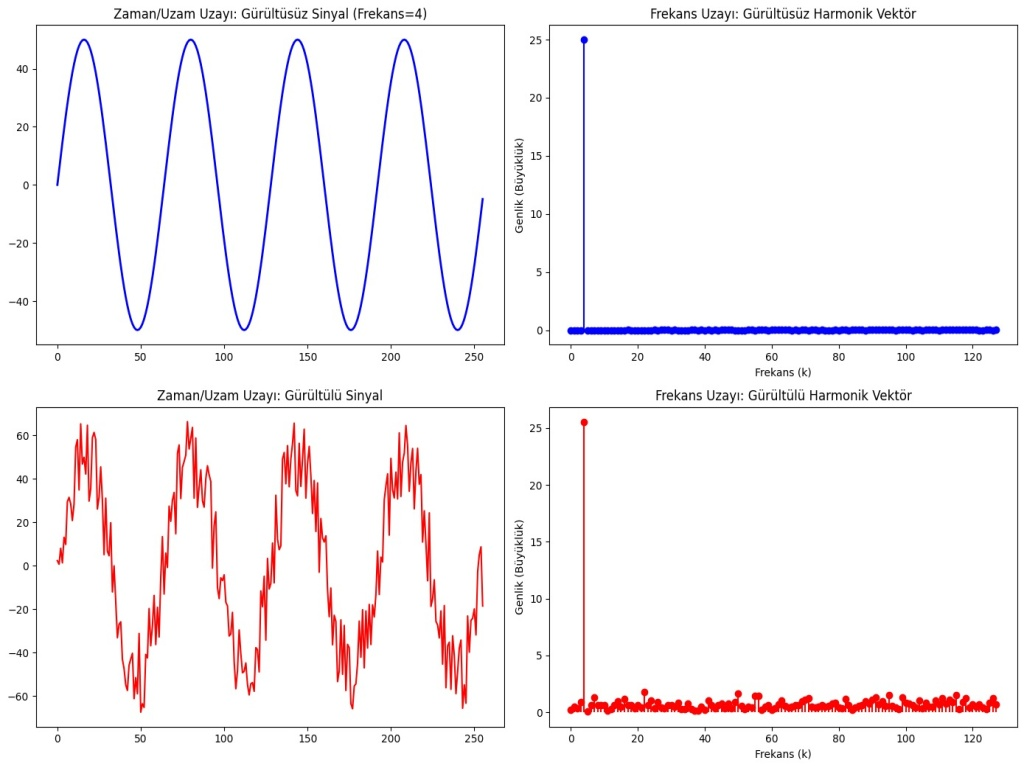

In [ ]:
ornek = os.listdir(cikti_dizini)[0]
sonuc = cv2.imread(os.path.join(cikti_dizini, ornek))
print(sonuc.shape)
cv2_imshow(sonuc)